# Práctica: LSTM con embeddings preentrenados (GloVe)

**Base:** Notebook 13 (*Ejemplo de aplicación de un modelo LSTM a la clasificación de textos*, AG_NEWS).

**Enunciado:** modificar el modelo LSTM del Notebook 13 para que use embeddings preentrenados GloVe, comprobar si mejora la precisión y ver qué pasa con los distintos tamaños (50, 100, 200 y 300 dimensiones).

### Qué cambia respecto al código base

| Parte del notebook 13 | ¿Cambia? |
|---|---|
| Dataset, tokenizador, `text_pipeline`, `collate_batch`, `DataLoader` | **No**, se copia tal cual |
| Descargar y leer GloVe | **Nuevo** (secciones 2 y 3) |
| Construir la matriz de embeddings | **Nuevo** (sección 4) |
| `LSTMTextClassificationModel` | **Solo cambia** cómo se crea `self.embedding` (sección 5) |
| `train` / `evaluate` | Igual, pero reciben el modelo y el optimizador como argumento para poder entrenar varios modelos (sección 6) |
| Hiperparámetros (`EPOCHS=10`, `LR=5`, SGD, `hidden_dim=64`, `batch_size=64`) | **No**, iguales para que la comparación sea justa |



## 1. Datos, tokenizador y DataLoaders 

Se añadió es la variable `device`, que elige la GPU si hay una y si no la CPU.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from datasets import load_dataset
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers


dataset = load_dataset("fancyzhx/ag_news")
train_ds = dataset["train"]
test_ds = dataset["test"]


tokenizer = Tokenizer(models.WordLevel(unk_token="<unk>"))
tokenizer.normalizer = normalizers.Lowercase()
tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
trainer = trainers.WordLevelTrainer(vocab_size=200_000, special_tokens=["<pad>", "<unk>"])
tokenizer.train_from_iterator(train_ds["text"], trainer=trainer)

text_pipeline = lambda x: tokenizer.encode(x).ids
PAD_IDX = tokenizer.token_to_id("<pad>")


def collate_batch(batch):
    label_list, text_list = [], []
    for sample in batch:
        text_list.append(torch.tensor(text_pipeline(sample["text"]), dtype=torch.long))
        label_list.append(sample["label"])
    return torch.tensor(label_list, dtype=torch.long), torch.nn.utils.rnn.pad_sequence(text_list, batch_first=True, padding_value=PAD_IDX)

train_dataloader = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=collate_batch)
test_dataloader = DataLoader(test_ds, batch_size=64, shuffle=True, collate_fn=collate_batch)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Tamaño del vocabulario:", tokenizer.get_vocab_size(), "| dispositivo:", device)

/Users/macbookpro/PLN/práctica 5/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/macbookpro/PLN/práctica 5/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
Generating test split: 100%|██████████| 7600/7600 [00:00<00:00, 2079367.93 examples/s]


Tamaño del vocabulario: 65355 | dispositivo: cpu


## 2. Descargar GloVe

**Qué hace:** descarga el zip de GloVe del Hub de Hugging Face (código que da el enunciado) y lista qué ficheros hay dentro.


In [2]:
from huggingface_hub import hf_hub_download
import zipfile

path = hf_hub_download(repo_id="stanfordnlp/glove", filename="glove.6B.zip")

with zipfile.ZipFile(path) as z:
    print(z.namelist())

['glove.6B.100d.txt', 'glove.6B.200d.txt', 'glove.6B.300d.txt', 'glove.6B.50d.txt']


## 3. Leer un fichero GloVe

Cada línea del fichero es una palabra seguida de los números de su vector, separados por espacios. Por ejemplo (recortado), en `glove.6B.50d.txt`:

```
the 0.418 0.24968 -0.41242 0.1217 ... (50 números en total)
```

### Función `load_glove(zip_path, dim, vocab)`

**Qué hace:** lee el fichero GloVe del tamaño elegido y se queda con el vector de cada palabra **que también está en nuestro vocabulario** (las otras ~340.000 no las necesitamos).

- **Entra:**
  - `zip_path` → ruta del zip (la `path` de antes).
  - `dim` → tamaño de los vectores: 50, 100, 200 o 300.
  - `vocab` → diccionario de nuestro tokenizador `{palabra: índice}` (sale de `tokenizer.get_vocab()`).
- **Sale:** `glove`, un diccionario `{palabra: vector}` donde cada vector es un array de numpy con `dim` números.


In [3]:
import io
import numpy as np

def load_glove(zip_path, dim, vocab):
    glove = {}
    filename = f"glove.6B.{dim}d.txt"
    with zipfile.ZipFile(zip_path) as z:
        with z.open(filename) as f:
            for line in io.TextIOWrapper(f, encoding="utf-8"):
                parts = line.rstrip().split(" ")
                word = parts[0]
                if word in vocab:
                    glove[word] = np.asarray(parts[1:], dtype=np.float32)
    return glove

vocab = tokenizer.get_vocab()          # {palabra: índice}
glove100 = load_glove(path, 100, vocab)

print("Palabras de nuestro vocabulario encontradas en GloVe:", len(glove100), "de", len(vocab))
print("Vector de 'football' (primeros 8 de 100 números):", glove100["football"][:8])

Palabras de nuestro vocabulario encontradas en GloVe: 57084 de 65355
Vector de 'football' (primeros 8 de 100 números): [ 0.43865   0.10537   0.45972  -1.0724   -1.2471    0.76351   0.47528
  0.083857]


### Comprobación: ¿los vectores GloVe tienen significado?

Ver por qué GloVe ayuda. Calculamos la **similitud coseno** entre vectores: cerca de 1 = apuntan en la misma dirección (palabras parecidas); cerca de 0 = no tienen relación.


In [4]:
def cos(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

def most_similar(word, k=5):
    sims = [(w, cos(glove100[word], v)) for w, v in glove100.items() if w != word]
    return sorted(sims, key=lambda x: x[1], reverse=True)[:k]

for w in ["football", "stocks", "software", "war"]:
    if w in glove100:
        print(w, "->", [(x, round(s, 2)) for x, s in most_similar(w)])

football -> [('soccer', 0.87), ('basketball', 0.86), ('league', 0.82), ('rugby', 0.8), ('hockey', 0.78)]
stocks -> [('stock', 0.83), ('shares', 0.8), ('market', 0.77), ('markets', 0.76), ('prices', 0.76)]
software -> [('computer', 0.84), ('hardware', 0.79), ('microsoft', 0.78), ('applications', 0.74), ('technology', 0.74)]
war -> [('wars', 0.77), ('conflict', 0.77), ('invasion', 0.74), ('military', 0.74), ('occupation', 0.73)]


## 4. Construir la matriz de embeddings

`nn.Embedding` es por dentro **una matriz** de tamaño `(vocab_size, embed_dim)`: la fila `i` es el vector de la palabra con índice `i`.Aquí **rellenamos con GloVe** (lla tabla de embbeding): la fila de cada palabra será su vector GloVe.

Problema: no todas nuestras palabras están en GloVe (nombres raros, erratas, `<unk>`…). Para esas filas ponemos números aleatorios, de la misma "escala" que los de GloVe. La fila de `<pad>` (índice 0) la ponemos a ceros, porque el relleno no significa nada.


In [5]:
def build_embedding_matrix(tokenizer, glove, dim):
    vocab_size = tokenizer.get_vocab_size()
    std = np.stack(list(glove.values())).std()
    rng = np.random.default_rng(0)
    matrix = rng.normal(0, std, size=(vocab_size, dim)).astype(np.float32)

    found = 0
    for word, idx in tokenizer.get_vocab().items():
        if word in glove:
            matrix[idx] = glove[word]
            found += 1
    matrix[PAD_IDX] = 0

    print(f"GloVe {dim}d: {found}/{vocab_size} palabras encontradas ({100 * found / vocab_size:.1f}%)")
    return torch.tensor(matrix)

emb100 = build_embedding_matrix(tokenizer, glove100, 100)
print("Forma de la matriz:", emb100.shape)
print("¿La fila de 'football' es su vector GloVe?",
      torch.allclose(emb100[tokenizer.token_to_id("football")], torch.tensor(glove100["football"])))

GloVe 100d: 57084/65355 palabras encontradas (87.3%)
Forma de la matriz: torch.Size([65355, 100])
¿La fila de 'football' es su vector GloVe? True


> **Cobertura por palabras vs. por tokens.** El porcentaje de arriba cuenta palabras *distintas*. Las que faltan suelen ser raras (aparecen 1 o 2 veces), así que si contamos **apariciones** en los textos, el porcentaje cubierto es mucho mayor. Esta celda lo mide sobre 5.000 noticias de entrenamiento:

In [6]:
total, cubiertos = 0, 0
for text in train_ds[:5000]["text"]:
    for tok in tokenizer.encode(text).tokens:
        total += 1
        cubiertos += tok in glove100
print(f"Tokens (apariciones) cubiertos por GloVe: {100 * cubiertos / total:.1f}%")

Tokens (apariciones) cubiertos por GloVe: 98.6%


## 5. Modelo LSTM modificado


In [7]:
class LSTMTextClassificationModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_class, pretrained_embeddings=None, freeze=True):
        super(LSTMTextClassificationModel, self).__init__()
        if pretrained_embeddings is None:
            self.embedding = nn.Embedding(vocab_size, embed_dim)          # <-- Notebook 13: aleatorio
        else:
            self.embedding = nn.Embedding.from_pretrained(pretrained_embeddings, freeze=freeze)  # <-- NUEVO: GloVe
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_class)

    def forward(self, text):
        embedded = self.embedding(text)
        lstm_out, _ = self.lstm(embedded)
        last_output = lstm_out[:, -1, :]
        output = self.fc(last_output)
        return output

# Prueba rápida con un mini-lote, como en el notebook 13
model = LSTMTextClassificationModel(tokenizer.get_vocab_size(), 100, 64, 4, pretrained_embeddings=emb100, freeze=True)
label, text = next(iter(train_dataloader))
print("Entrada:", text.shape, "-> tras embedding:", model.embedding(text).shape, "-> salida:", model(text).shape)
print("¿Se entrena la capa de embedding?", model.embedding.weight.requires_grad)

Entrada: torch.Size([64, 98]) -> tras embedding: torch.Size([64, 98, 100]) -> salida: torch.Size([64, 4])
¿Se entrena la capa de embedding? False


## 6. `train` y `evaluate`


In [8]:
import time

EPOCHS = 10   # igual que el notebook 13
LR = 5        # igual que el notebook 13
criterion = torch.nn.CrossEntropyLoss()

def train(model, optimizer, dataloader):
    model.train()
    total_acc, total_count = 0, 0
    log_interval = 500
    for idx, (label, text) in enumerate(dataloader):
        label, text = label.to(device), text.to(device)
        optimizer.zero_grad()
        predicted_label = model(text)
        loss = criterion(predicted_label, label)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
        optimizer.step()
        total_acc += (predicted_label.argmax(1) == label).sum().item()
        total_count += label.size(0)
        if idx % log_interval == 0 and idx > 0:
            print('| {:5d} batches | accuracy {:8.3f}'.format(idx, total_acc / total_count))
            total_acc, total_count = 0, 0

def evaluate(model, dataloader):
    model.eval()
    total_acc, total_count = 0, 0
    with torch.no_grad():
        for label, text in dataloader:
            label, text = label.to(device), text.to(device)
            predicted_label = model(text)
            total_acc += (predicted_label.argmax(1) == label).sum().item()
            total_count += label.size(0)
    return total_acc / total_count

## 7. Función para lanzar un experimento

**Qué hace:** crea un modelo nuevo, lo entrena `EPOCHS` épocas y guarda la precisión en test de cada época.


In [9]:
results = {}

def run_experiment(name, embed_dim, pretrained=None, freeze=True):
    if name in results:
        return results[name]
    print(f"\n===== {name} =====")
    torch.manual_seed(0)
    model = LSTMTextClassificationModel(tokenizer.get_vocab_size(), embed_dim, 64, 4,
                                        pretrained_embeddings=pretrained, freeze=freeze).to(device)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parámetros entrenables: {n_train:,}")
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)

    history = []
    for epoch in range(1, EPOCHS + 1):
        epoch_start_time = time.time()
        train(model, optimizer, train_dataloader)
        accu_val = evaluate(model, test_dataloader)
        history.append(accu_val)
        print("-" * 59)
        print("| end of epoch {:3d} | time: {:5.2f}s | valid accuracy {:8.3f} ".format(
            epoch, time.time() - epoch_start_time, accu_val))
        print("-" * 59)
    results[name] = history
    return history

## 8. Prueba A — ¿Mejora la precisión con GloVe?


In [10]:
run_experiment("Aleatorio 100d", 100)
run_experiment("GloVe 100d congelado", 100, pretrained=emb100, freeze=True)
run_experiment("GloVe 100d ajustado", 100, pretrained=emb100, freeze=False)


===== Aleatorio 100d =====
Parámetros entrenables: 6,578,256
|   500 batches | accuracy    0.255
|  1000 batches | accuracy    0.272
|  1500 batches | accuracy    0.513
-----------------------------------------------------------
| end of epoch   1 | time: 43.23s | valid accuracy    0.637 
-----------------------------------------------------------
|   500 batches | accuracy    0.686
|  1000 batches | accuracy    0.748
|  1500 batches | accuracy    0.782
-----------------------------------------------------------
| end of epoch   2 | time: 43.12s | valid accuracy    0.804 
-----------------------------------------------------------
|   500 batches | accuracy    0.823
|  1000 batches | accuracy    0.837
|  1500 batches | accuracy    0.841
-----------------------------------------------------------
| end of epoch   3 | time: 44.09s | valid accuracy    0.851 
-----------------------------------------------------------
|   500 batches | accuracy    0.868
|  1000 batches | accuracy    0.871

[0.2561842105263158,
 0.8907894736842106,
 0.9123684210526316,
 0.9163157894736842,
 0.9193421052631578,
 0.9217105263157894,
 0.9251315789473684,
 0.9244736842105263,
 0.9263157894736842,
 0.9281578947368421]

## 9. Prueba B — ¿Qué pasa con los distintos tamaños?

Repetimos con GloVe congelado para 50, 100, 200 y 300 dimensiones (el de 100 ya está hecho y se reutiliza). Para cada tamaño hay que leer **su** fichero y construir **su** matriz, porque el vector de una palabra en `50d` no tiene nada que ver con el de `300d`: son entrenamientos distintos.

Si en el experimento A te sale claramente mejor `freeze=False`, puedes cambiar `FREEZE_B = False` (el nombre del experimento se ajusta solo).

In [11]:
FREEZE_B = True
etiqueta = "congelado" if FREEZE_B else "ajustado"

for dim in [50, 100, 200, 300]:
    name = f"GloVe {dim}d {etiqueta}"
    if name in results:
        continue
    glove = load_glove(path, dim, vocab)
    emb = build_embedding_matrix(tokenizer, glove, dim)
    run_experiment(name, dim, pretrained=emb, freeze=FREEZE_B)
    del glove, emb   # libera memoria antes del siguiente tamaño

GloVe 50d: 57084/65355 palabras encontradas (87.3%)

===== GloVe 50d congelado =====
Parámetros entrenables: 29,956
|   500 batches | accuracy    0.253
|  1000 batches | accuracy    0.251
|  1500 batches | accuracy    0.298
-----------------------------------------------------------
| end of epoch   1 | time: 37.41s | valid accuracy    0.475 
-----------------------------------------------------------
|   500 batches | accuracy    0.452
|  1000 batches | accuracy    0.705
|  1500 batches | accuracy    0.867
-----------------------------------------------------------
| end of epoch   2 | time: 36.77s | valid accuracy    0.882 
-----------------------------------------------------------
|   500 batches | accuracy    0.883
|  1000 batches | accuracy    0.885
|  1500 batches | accuracy    0.893
-----------------------------------------------------------
| end of epoch   3 | time: 36.91s | valid accuracy    0.897 
-----------------------------------------------------------
|   500 batches |

## 10. Resultados

Experimento                   Época 1    Final    Mejor
--------------------------------------------------------
Aleatorio 100d                  0.637    0.887    0.887
GloVe 100d congelado            0.452    0.920    0.920
GloVe 100d ajustado             0.256    0.928    0.928
GloVe 50d congelado             0.475    0.917    0.917
GloVe 200d congelado            0.796    0.923    0.923
GloVe 300d congelado            0.261    0.921    0.923


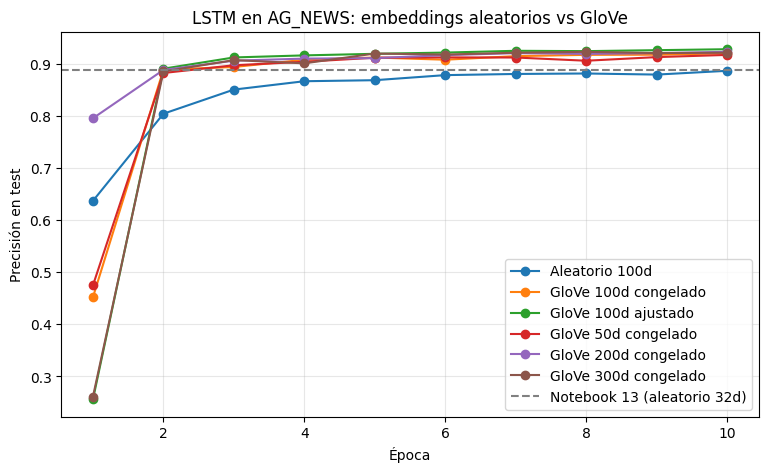

In [12]:
import matplotlib.pyplot as plt

print(f"{'Experimento':28s} {'Época 1':>8s} {'Final':>8s} {'Mejor':>8s}")
print("-" * 56)
for name, h in results.items():
    print(f"{name:28s} {h[0]:8.3f} {h[-1]:8.3f} {max(h):8.3f}")

plt.figure(figsize=(9, 5))
for name, h in results.items():
    plt.plot(range(1, len(h) + 1), h, marker="o", label=name)
plt.axhline(0.889, color="gray", linestyle="--", label="Notebook 13 (aleatorio 32d)")
plt.xlabel("Época")
plt.ylabel("Precisión en test")
plt.title("LSTM en AG_NEWS: embeddings aleatorios vs GloVe")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 11. Conclusiones (rellenar con tus resultados)

**¿Se produce una mejora con GloVe?** Mira dos cosas en la tabla:
- *Velocidad*: la precisión en la época 1. En el notebook 13 el modelo aleatorio empezaba en 0.458, porque tiene que aprender desde cero qué significa cada palabra. Con GloVe parte de vectores que ya agrupan palabras parecidas.
- *Precisión final*: compara la época 10 de "Aleatorio 100d" con las de GloVe.
- *Congelado vs ajustado*: ajustado tiene muchos más parámetros entrenables (65.355 × 100 ≈ 6,5 millones), puede adaptar GloVe a noticias pero también sobreajustar (mira la diferencia entre la precisión de entrenamiento de los logs y la de test).

**¿Qué ocurre con los distintos tamaños?** Más dimensiones = vectores con más información, pero también más cálculo en la LSTM (la entrada es mayor) y más memoria. Fíjate en si la mejora de 50 → 100 → 200 → 300 es grande o se estanca, y en el tiempo por época.

_Escribe aquí tus conclusiones con los números de la tabla._